<a id="exercises"></a>
# Part 4 — Your turn 🎓

These exercises are the actual point of the notebook. Work through them; bring your plots and
questions to the next onboarding session.

### Exercise 1 — Make a plot of your own (required)

Pick a quantity from §3.2 that we did **not** plot and make a figure of it against time, with a
sentence or two explaining what it shows. Good candidates:

- `Luminosity(1)` and `Luminosity(2)` vs time (use a log y-axis).
- `Teff(1)` and `Teff(2)` vs time — when is each star hottest, and why?
- `Mass_CO_Core` vs `Mass_He_Core` — how does the onion-layer structure build up?
- `Mass_Env(1)` (the envelope mass) — watch it get stripped to zero.
- The **mass ratio** $q = M_2/M_1$ vs time. Mark the moment it crosses 1.

Matplotlib is building the font cache; this may take a moment.


Mass ratio crosses 1 at 6.13 Myr


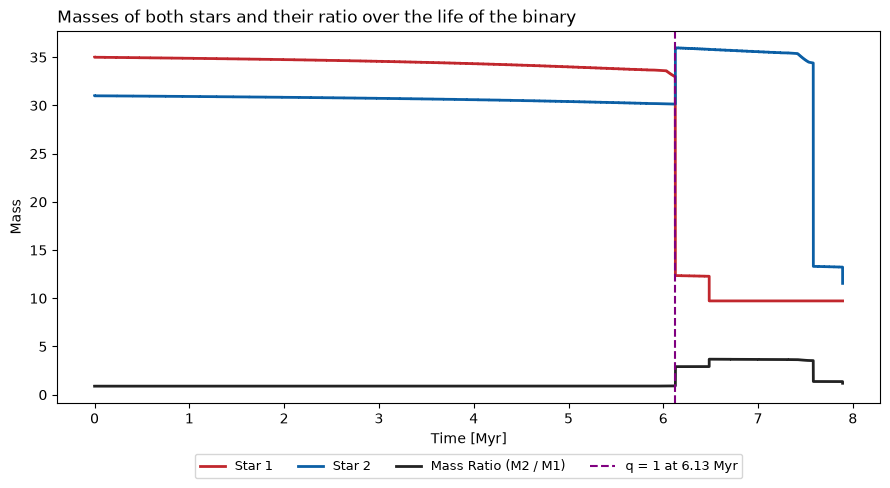

In [1]:
# --- Exercise 1: your plot here -------------------------------------------------
# Hint: `df` already holds the columns listed in COLUMNS. To load a different column,
# add its name to COLUMNS and re-run §3.2, or open the file directly:



import h5py
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

COLUMNS = [
    "Time", "dT",
    "Mass(1)", "Mass(2)", "Mass_He_Core(1)", "Mass_He_Core(2)",
    "Mass_CO_Core(1)", "Mass_CO_Core(2)",
    "Radius(1)", "Radius(2)", "RocheLobe(1)", "RocheLobe(2)",
    "SemiMajorAxis", "Eccentricity",
    "Stellar_Type(1)", "Stellar_Type(2)",
    "Luminosity(1)", "Luminosity(2)", "Teff(1)", "Teff(2)",
    "MT_History", "Unbound",
]

DATA_PATH = Path("../BSE_Detailed_Output_0.h5")
with h5py.File(DATA_PATH, "r") as f:
    df = pd.DataFrame({c: f[c][()] for c in COLUMNS})
    m1, m2 = f["Mass(1)"][()], f["Mass(2)"][()] # [()] reads the dataset values as a NumPy array.
    m21 = m2 / m1
    time = f["Time"][()]

# Find the first time the mass ratio crosses q = 1.
crossings = np.where((m21[:-1] - 1) * (m21[1:] - 1) <= 0)[0]
t_cross = None
if len(crossings) > 0:
    i = crossings[0]
    if m21[i] == 1:
        t_cross = time[i]
    else:
        # linear interpolation is the fancy word for this
        t_cross = time[i] + (1 - m21[i]) * (time[i + 1] - time[i]) / (m21[i + 1] - m21[i])
    print(f"Mass ratio crosses 1 at {t_cross:.2f} Myr")
else:
    print("The mass ratio does not cross 1.")

fig, ax = plt.subplots(figsize=(9, 5)) # sets up framework 
C1, C2, CSYS = "#C1272D", "#0B5FA5", "#222222"

ax.plot(time, m1, color=C1, lw=2, label="Star 1")
ax.plot(time, m2, color=C2, lw=2, label="Star 2")
ax.plot(time, m21, color=CSYS, lw=2, label="Mass Ratio (M2 / M1)")

if t_cross is not None:
    ax.axvline(t_cross, color="purple", linestyle="--", lw=1.5,
                label=f"q = 1 at {t_cross:.2f} Myr")

ax.set_xlabel("Time [Myr]")
ax.set_ylabel("Mass")
ax.set_title("Masses of both stars and their ratio over the life of the binary", loc="left", fontsize=12)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=9, ncol=4)

plt.tight_layout()
plt.show()

### Exercise 2 — Predict, then check

**Before running anything**, write down your prediction for each, then go back to GWLandscape
(§1.2 "Also try") and test it:

1. If you increase the metallicity to Z = 0.02 (above solar), will the final black holes be
   **more** or **less** massive? Why?
2. If you start the binary at 35 AU instead of 3.5 AU, will there be a common envelope?
   What will the final separation be? Will these black holes ever merge?
3. If you make the two stars equal mass (33 and 33 M$_\odot$), does star 1 still get stripped first?

Download the output of one of these runs and re-run the analysis cells above on it — just change
`DATA_PATH`. Everything else should work unchanged.

### Exercise 3 — Will they merge? (stretch)

Our binary ends as two black holes ($m_1 \approx 9.7$, $m_2 \approx 11.5$ M$_\odot$) with
$a \approx 9.9$ R$_\odot$ and $e \approx 0$. Two black holes in orbit emit **gravitational waves**,
which carry away energy, so the orbit shrinks until they merge. For a circular orbit, Peters
(1964) gives the time to merge as:

$$ t_{\rm merge} = \frac{5}{256} \, \frac{c^5 \, a^4}{G^3 \, m_1 \, m_2 \, (m_1 + m_2)} $$

Compute $t_{\rm merge}$ for our system. **Is it less than the age of the Universe (13.8 Gyr)?**
If so, congratulations — you have just built a LIGO source from scratch. Then try it with the
pre-common-envelope separation of ~2110 R$_\odot$ and see just how much that one event mattered.

*(Watch your units — the formula needs SI. Note $t \propto a^4$: this is why the factor-230
shrink in $a$ matters so enormously. If you have a working `astropy` install, `astropy.units`
and `astropy.constants` will keep your units honest for you; the stub below uses plain SI
constants so that it runs anywhere.)*

In [ ]:
# --- Exercise 3: merger time ----------------------------------------------------
# SI constants, so this cell has no extra dependencies.
'''
G_SI = 6.67430e-11      # m^3 kg^-1 s^-2
C_SI = 2.99792458e8     # m s^-1
MSUN = 1.98892e30       # kg
RSUN = 6.957e8          # m
GYR = 3.15576e16        # s
'''
from astropy import units as u
from astropy import constants as const

def merger_time(m1_msun, m2_msun, a_rsun):
    '''Peters (1964) gravitational-wave merger timescale for a circular orbit.

    Returns the time to merge in Gyr.
    '''
    #m1, m2, a = m1_msun * MSUN, m2_msun * MSUN, a_rsun * RSUN
    m1 = m1_msun * u.M_sun
    m2 = m2_msun * u.M_sun
    a = a_rsun * u.R_sun

    t_merge = (5 / 256) * const.c**5 * a**4 / (const.G**3 * m1 * m2 * (m1 + m2)) # astropy object

    return t_merge.to(u.Gyr) # astropy function to convert to Gyr

t = merger_time(df["Mass(1)"].iloc[-1], df["Mass(2)"].iloc[-1], df["SemiMajorAxis"].iloc[-1])
print(f"merger time = {t:.3f} Gyr | (age of the Universe = 13.8 Gyr)")

merger time = 0.606 Gyr Gyr  (age of the Universe = 13.8 Gyr)


**Exercise 1**

The plot shows how the masses of both stars change over time and how they compare with each other over time. Star 1 starts more massive but loses mass, weighing lighter than Star 2 eventually. Their mass ratio (M_2 / M_1) crosses 1 at around 6.13 Myr, which is when they have equal masses. 

**Exercise 2** - Predictions

1. Less massive. There's a lot of outward pressure from the released energy in the fusion reactions, so the stellar winds are stronger, blowing off more of the outer layer. Over time, the outer layer gets smaller. The core has more limited resources to continue fusion. The starved core that remains is smaller, leaving behind a small black hole in the end. 
2. There probably won't be a common envelope because the stars are very far apart. I don't know what the final separation will be. I don't know if the black holes will merge. 
3. Probably not because mass dictates lifespan, and they have the same mass. 
